# Notebook 1: Explainable AI (XAI) -- LIME on tabular data

## Course: Big Data Analytics
## University of Milano-Bicocca
## Degree Programme: Economics, Data Analysis and Management

---

### Introduction

A model can have a good accuracy and still be **right for the wrong reasons**. In this notebook we:

1. **train** a black-box model that decides on **mortgage applications** (Part 1);
2. **open** it with **LIME**, *Local Interpretable Model-agnostic Explanations*: first **by hand**, to see every detail of how it works, then with the library, and we check whether the explanation can be **trusted** (*fidelity*) (Part 2);
3. **use** what LIME shows us to **audit and fix** the model (Part 3);
4. see the **limits** of LIME (Part 4).

> 📚 **The series**: **1. LIME · tabular** (this notebook) → 2. LIME · text → 3. SHAP · tabular → 4. SHAP · text. Notebooks 1 and 3 explain **the same mortgage model**: same data, same training, only the explainer changes.

# IMAGINE: A BANK'S ALGORITHM REJECTS YOUR MORTGAGE. WOULD YOU ACCEPT "THE MODEL SAID NO" AS THE ONLY ANSWER?

---

## Why do we need explanations?

Random Forests, Gradient Boosting and neural networks are **black boxes**: we see the input and the output, not the reasoning. In credit decisions this is not enough:

- ⚖️ **Law**: in the EU, AI systems that assess creditworthiness are **high-risk** under the *AI Act*; in the US, a lender must tell a rejected applicant the **main reasons** for the denial.
- 🚫 **Fairness**: protected attributes (race, sex, ...) must not drive the decision, and we can only check this by looking inside the model.
- 🐛 **Debugging**: explanations reveal what the model has *really* learned.

> **Global** explanations describe the whole model; **local** explanations answer the question *"why THIS decision?"*. LIME is a **local** method.

In [ ]:
# ==========================================
# 1. SETUP: INSTALL AND IMPORT
# ==========================================

# LIME is not pre-installed on Colab: we install it with pip ("!" runs a shell command)
!pip install lime --quiet

import warnings
import numpy as np                       # numbers and arrays
import pandas as pd                      # tables (DataFrame)
import matplotlib.pyplot as plt          # charts
from IPython.display import HTML, display

from sklearn.model_selection import train_test_split     # split the data into train and test
from sklearn.ensemble import RandomForestClassifier      # our black box
from sklearn.linear_model import Ridge                   # the simple linear model used by LIME
from sklearn.metrics import accuracy_score, roc_auc_score

from lime.lime_tabular import LimeTabularExplainer        # LIME for tables

warnings.filterwarnings("ignore")    # hide technical warnings, to keep the output readable
np.random.seed(42)                   # fix the random numbers: same results at every run

# Colors of our own charts (a palette that colorblind readers can tell apart)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 150)   # show long texts in full inside tables

def dumbbell(table, xlabel, title, fmt="{:.1%}"):
    # Helper for "before vs after" charts.
    # 'table' has one row per item and two columns: [before, after]. Each row becomes a line
    # with a gray dot (before) and a blue dot (after), and the two values written next to the dots.
    before, after = table.columns
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.55 * len(table)))
    for i, (a, b) in enumerate(table.values):
        ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)                     # the line
        ax.scatter(a, i, s=110, color=GRAY, edgecolors="white", lw=2, zorder=2, label=before if i == 0 else None)
        ax.scatter(b, i, s=110, color=BLUE, edgecolors="white", lw=2, zorder=3, label=after if i == 0 else None)
        ax.annotate(fmt.format(a), (a, i), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=8)
        ax.annotate(fmt.format(b), (b, i), xytext=(0, -15), textcoords="offset points", ha="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.set_title(title, loc="left", pad=26)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout()
    plt.show()

def show_lime(explanation, **kwargs):
    # Shows LIME's interactive view (same as explanation.show_in_notebook(), but works with every IPython version)
    display(HTML(explanation.as_html(**kwargs)))

print("✅ Setup complete")

# 🏗️ Part 1 — Train the black box

This is the **training** of the mortgage model. **Notebook 3** (SHAP) repeats exactly this part (same data, same split, same random seeds), so it explains **the identical model**.

## 1.1 🏦 The data: mortgage applications

The **Boston HMDA** data (Munnell et al., 1996; also used in Stock & Watson's *Introduction to Econometrics*) contains **2,380 real mortgage applications** collected by the Federal Reserve Bank of Boston. Each row is one application; each column is a **feature** (a characteristic of the applicant). We use 9 features:

| Feature | Meaning | Original name |
| :--- | :--- | :---: |
| `debt_to_income` | total debt payments / income (0.33 = 33% of the income goes to debts) | `pirat` |
| `housing_to_income` | housing expenses / income | `hirat` |
| `loan_to_value` | loan / value of the property (0.90 = the bank lends 90% of the price) | `lvrat` |
| `credit_problems` | consumer credit history: 1 = no late payments, 2 = one or two late payments, 3 = more than two, 4 = not enough history, 5 = payments 60 days overdue, 6 = 90 days overdue (**higher = worse**) | `chist` |
| `mortgage_problems` | mortgage payment history: 1 = no late payments, 2 = no mortgage history, 3 = one or two late payments, 4 = more than two (**higher = worse**) | `mhist` |
| `public_bad_record` | public record of credit problems (e.g. bankruptcy)? 1 = yes | `phist` |
| `self_employed` | self-employed? 1 = yes | `selfemp` |
| `single` | single? 1 = yes | `single` |
| `african_american` | African-American applicant? 1 = yes ⚠️ **protected attribute** (by law it must not influence the decision) | `afam` |

**Target** (what the model must predict): `deny` = 1 if the mortgage was denied, 0 if it was approved.

In [ ]:
# ==========================================
# 2. LOAD THE MORTGAGE DATA
# ==========================================

# The data is a CSV file on GitHub: pandas downloads and reads it in one line
URL_HMDA = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/HMDA.csv"
hmda = pd.read_csv(URL_HMDA)

# Clearer names for the columns we use (original names of the dataset on the left)
hmda = hmda.rename(columns={
    'pirat': 'debt_to_income',   'hirat': 'housing_to_income', 'lvrat': 'loan_to_value',
    'chist': 'credit_problems',  'mhist': 'mortgage_problems', 'phist': 'public_bad_record',
    'selfemp': 'self_employed',  'afam': 'african_american'})

# The 9 features we use. The file has a few more: e.g. 'insurance' (= a separate insurer
# refused the applicant) is almost a copy of the outcome, so we leave it out.
FEATURES = ['debt_to_income', 'housing_to_income', 'loan_to_value', 'credit_problems', 'mortgage_problems',
            'public_bad_record', 'self_employed', 'single', 'african_american']

# The yes/no columns are stored as text ('yes'/'no'): we turn them into 1/0
for col in ['deny', 'public_bad_record', 'self_employed', 'single', 'african_american']:
    hmda[col] = (hmda[col] == 'yes').astype(int)

X = hmda[FEATURES]      # the features (inputs of the model)
y = hmda['deny']        # the target (1 = denied)

print(f"{len(hmda)} applications | denied: {y.mean():.1%}")
X.head()                # the first 5 applications

## 1.2 🌲 The black box: a Random Forest

- A **decision tree** decides with a sequence of yes/no questions (*"is `loan_to_value` > 0.9?"* → *"is `credit_problems` > 2?"* → ...).
- A **Random Forest** trains **100 trees**, each on a random part of the data, and averages their answers. The result is **P(deny)**, the probability that the application is denied. It is more accurate than a single tree, but impossible to read: 100 trees with hundreds of questions each. This is our **black box**.

**How we evaluate it.** We put 25% of the applications aside (the **test set**) and never show them to the model during training. On the test set we measure:
- **accuracy**: the share of applications where the decision (deny when P(deny) > 0.5) is correct;
- **ROC-AUC**: the probability that a randomly chosen *denied* applicant gets a **higher** P(deny) than a randomly chosen *approved* one (0.5 = random guessing, 1 = perfect ranking). Here it is more informative than accuracy, because only 12% of the applications are denied.

In [ ]:
# ==========================================
# 3. TRAIN THE MORTGAGE BLACK BOX (RANDOM FOREST)
# ==========================================

# Split: 75% of the applications to train the model, 25% to test it.
# stratify=y keeps the same share of denials (12%) in both parts; random_state=42 fixes the random split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
# Number the test applicants 0, 1, 2, ... ("applicant #112" = row 112 of the test set)
X_test, y_test = X_test.reset_index(drop=True), y_test.reset_index(drop=True)

def train_mortgage_model(X, y):
    # Our black box: a forest of 100 decision trees (n_estimators=100). Every final group of a tree
    # must contain at least 10 applicants (min_samples_leaf=10): the trees cannot memorise single cases
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=42).fit(X, y)

mortgage_model = train_mortgage_model(X_train, y_train)

# predict_proba returns two columns, [P(approve), P(deny)]: we keep column 1 = P(deny)
p_deny = mortgage_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, p_deny)
print(f"Accuracy: {accuracy_score(y_test, p_deny > 0.5):.3f}  (careful: approving everybody already gives {1 - y_test.mean():.3f})")
print(f"ROC-AUC:  {auc:.4f}  (0.5 = random ranking, 1 = perfect ranking)")

# The "fingerprint": two numbers that identify this exact model
print(f"\n🔑 Fingerprint of the model: AUC = {auc:.4f} | P(deny) of applicant #112 = {p_deny[112]:.3f}")
print("   (identical in Notebooks 1 and 3: same data, same code, same seeds -> same model)")

The model ranks applicants well (ROC-AUC ≈ 0.81). **But why does it decide what it decides?** Let's open it.

# 🔍 Part 2 — How LIME works

## 2.1 The idea

> A complex model can be **locally** approximated by a simple one.

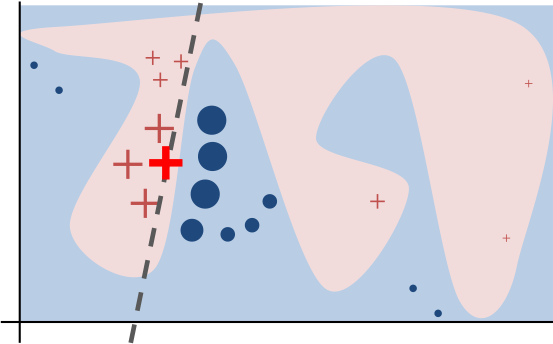

*The intuition behind LIME. Figure from the LIME repository (Ribeiro, Singh & Guestrin, 2016; © 2016 Marco Tulio Ribeiro, BSD licence).*

| In the figure | What it means |
| :--- | :--- |
| blue / pink background | the decision function of the black box $f$: complex, no single line can describe it |
| bold red cross | the instance we want to explain (here: applicant #112) |
| red crosses and blue dots | **perturbed copies** of the instance (copies with some changes), with the class predicted by the black box |
| size of a symbol | its **weight**: copies close to the instance count more |
| dashed line | the **explanation**: a linear model that is faithful **near** the instance, not everywhere |

The Earth is round, but the street in front of your house looks flat: in the same way, around **one** instance a black box can be approximated by a **linear model** (a weighted sum of the features), and the coefficients of that linear model are the explanation.

## 2.2 The formula

$$\xi(x) \;=\; \arg\min_{g \in G} \; \mathcal{L}\bigl(f, g, \pi_x\bigr) \;+\; \Omega(g)$$

*"Among the simple models $g$, choose the one that best imitates $f$ near $x$, while staying simple."*

- $f$: the black box; $x$: the instance to explain; $g \in G$: a simple (linear) model;
- $\mathcal{L}(f, g, \pi_x) = \sum_{z} \pi_x(z)\,\bigl(f(z) - g(z')\bigr)^2$: **local fidelity loss**, a weighted squared error over perturbed copies $z$ of $x$, where $z'$ is their 0/1 representation (for each feature: "is it still in the range of $x$?");
- $\pi_x(z) = \exp\!\bigl(-D(x,z)^2 / 2\sigma^2\bigr)$: **proximity kernel**, copies similar to $x$ weigh more ($D$ = distance from $x$, $\sigma$ = kernel width);
- $\Omega(g)$: **complexity** of $g$ (e.g. number of features used), kept small so that a human can read it.

## 2.3 The recipe in 4 steps (tabular data)

| Step | What LIME does to explain applicant $x$ |
| :--- | :--- |
| **1. Perturb** | create thousands of **copies** of $x$. In every copy **each feature is drawn again**: it takes the value of a **random applicant** of the training data, a different applicant for every feature |
| **2. Predict** | ask the black box P(deny) for every copy |
| **3. Weight** | copies that kept **more features in the range of $x$** are closer to $x$ and weigh more |
| **4. Fit** | a **weighted linear regression**: "feature still in the range of $x$" (1/0) → P(deny). *Weighted* = copies with a larger weight count more in the fit |

**What is a "range"?** Each numeric feature is cut at its **quartiles**, the values that split the training applicants into 4 groups of 25% each: e.g. `loan_to_value > 0.86` = the 25% of applicants with the highest loan-to-value. `credit_problems` and `mortgage_problems` take only a few integer values, so some cuts coincide: they get 3 ranges of unequal size. For a yes/no feature, the range is the value itself (e.g. `public_bad_record=yes`). LIME's question becomes: *"what happens to P(deny) when the loan-to-value is **not** in the top quartile any more?"*

**How many features change in each copy?** Nobody chooses it: it is **random**. A redrawn feature stays in the range of $x$ with a probability equal to the share of training applicants in that range: 25% for `loan_to_value > 0.86`, only 8% for `public_bad_record=yes` (only 8% of the training applicants have a public bad credit record). So every copy changes a different number of features: we count them in Section 2.4.

**What you can set** (in `LimeTabularExplainer` and in its method `explain_instance`):

| Parameter | Default | What it controls |
| :--- | :--- | :--- |
| `num_samples` | 5,000 | how many copies |
| `kernel_width` | $0.75\sqrt{\text{number of features}}$ | how quickly a copy loses weight when it changes more features |
| `discretizer` | `'quartile'` | what a "range" is (`'quartile'`, `'decile'`, ...): narrower ranges → more features change in each copy |
| `num_features` | 10 | how many features the explanation shows |

The **coefficients** of step 4 are the explanation: **+** pushes toward denial, **−** toward approval.

## 2.4 🔧 LIME by hand (no library)

We explain applicant **#112** of the test set (row 112 of `X_test`).

In [ ]:
# ==========================================
# 4. THE APPLICANT TO EXPLAIN
# ==========================================

APPLICANT = 112
applicant = X_test.iloc[APPLICANT]          # the 9 feature values of applicant #112

display(X_test.iloc[[APPLICANT]])           # show them as a one-row table
print(f"True outcome: {'DENIED' if y_test[APPLICANT] else 'approved'} | Model: P(deny) = {p_deny[APPLICANT]:.3f}")

In [ ]:
# ==========================================
# 5. LIME BY HAND - STEP 0: THE RANGES OF THE APPLICANT
# ==========================================

NUMERIC = ['debt_to_income', 'housing_to_income', 'loan_to_value', 'credit_problems', 'mortgage_problems']
BINARY  = ['public_bad_record', 'self_employed', 'single', 'african_american']

# Numeric features are cut at their quartiles (25th, 50th, 75th percentile), computed on the training data.
# np.unique removes duplicated cuts (e.g. when the 25th and the 50th percentile are the same integer)
edges = {f: np.unique(np.percentile(X_train[f], [25, 50, 75])) for f in NUMERIC}

def range_index(f, values):
    # numeric feature -> number of its range (0 = lowest); yes/no feature -> the value itself (0 or 1)
    return np.searchsorted(edges[f], values) if f in NUMERIC else np.asarray(values)

def range_name(f, value):
    # a readable name for the range of 'value', e.g. "loan_to_value > 0.86" or "public_bad_record=yes"
    if f in BINARY:
        return f"{f}={'yes' if value == 1 else 'no'}"
    e, k = edges[f], int(range_index(f, value))
    if k == 0:
        return f"{f} <= {e[0]:.2f}"            # lowest range
    if k == len(e):
        return f"{f} > {e[-1]:.2f}"            # highest range
    return f"{e[k-1]:.2f} < {f} <= {e[k]:.2f}" # a middle range

names = [range_name(f, applicant[f]) for f in FEATURES]   # the 9 ranges of applicant #112
pd.DataFrame({"value": applicant.round(3), "range of the applicant": names})

In [ ]:
# ==========================================
# 6. LIME BY HAND - STEP 1 (PERTURB) AND STEP 2 (PREDICT)
# ==========================================

N_SAMPLES = 5000                            # how many copies (LIME's default)
rng = np.random.RandomState(0)              # random numbers with a fixed seed

# STEP 1: in every copy, EVERY feature is drawn again: it takes the value of a RANDOM training
#         applicant, chosen independently for each feature.
# donors[i, j] = row of X_train that gives the value of feature j to copy i
donors = rng.randint(0, len(X_train), size=(N_SAMPLES - 1, len(FEATURES)))
random_values = pd.DataFrame({f: X_train[f].values[donors[:, j]] for j, f in enumerate(FEATURES)})
copies = pd.concat([X_test.iloc[[APPLICANT]], random_values], ignore_index=True)   # row 0 = the applicant himself

# STEP 2: ask the black box P(deny) for every copy
p_copies = mortgage_model.predict_proba(copies)[:, 1]

print(f"{N_SAMPLES:,} copies of applicant #{APPLICANT}. Row 0 is the applicant, rows 1-3 are three copies:")
copies.head(4).assign(**{"P(deny)": p_copies[:4].round(3)})

In [ ]:
# ==========================================
# 7. LIME BY HAND - HOW MANY FEATURES CHANGE IN EACH COPY?
# ==========================================

# Z[i, j] = 1 if feature j of copy i is still in the applicant's range, 0 if it changed range.
# Z is the 0/1 representation z' of the formula: the input of LIME's linear model
Z = pd.DataFrame({f: (range_index(f, copies[f]) == range_index(f, applicant[f])).astype(int) for f in FEATURES})

# Copy #1 under the microscope: where does each value come from?
print("Copy #1, feature by feature:")
display(pd.DataFrame({
    f"applicant #{APPLICANT}": applicant.round(3).values,
    "copy #1": copies.iloc[1].round(3).values,
    "value taken from": [f"training applicant #{i}" for i in donors[0]],
    "still in the applicant's range?": np.where(Z.iloc[1] == 1, "yes", "NO, changed")}, index=FEATURES))

keep_share = Z.iloc[1:].mean()                          # how often each feature keeps the applicant's range
n_changed = len(FEATURES) - Z.iloc[1:].sum(axis=1)     # how many features changed, copy by copy

# Left: share of copies that keep each range. Right: how many features change per copy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
order = keep_share.sort_values().index
bars = ax1.barh([range_name(f, applicant[f]) for f in order], keep_share[order], color=BLUE, height=0.6)
ax1.bar_label(bars, labels=[f"{share:.0%}" for share in keep_share[order]], padding=3, color=INK, fontsize=8)
ax1.set_xlim(0, 1.1)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlabel("share of the copies that keep the applicant's range")
ax1.set_title("Each feature keeps its range with its own probability", loc="left")
counts = n_changed.value_counts().reindex(range(len(FEATURES) + 1), fill_value=0)
ax2.bar(counts.index, counts.values, color=GRAY, width=0.7)
ax2.axvline(n_changed.mean(), color=ORANGE, lw=2)       # orange line = average
ax2.set_xticks(range(len(FEATURES) + 1))
ax2.set_xlabel("number of features that changed range")
ax2.set_ylabel("copies")
ax2.set_title(f"On average {n_changed.mean():.1f} of {len(FEATURES)} features change", loc="left")
plt.tight_layout()
plt.show()

💡 **Every copy is built with values taken from other applicants of the training data**, one feature at a time and from a different applicant each time.

**Nobody sets how many features change**: a frequent range (e.g. `self_employed=no`) is kept in most copies, a rare one (e.g. `public_bad_record=yes`) is almost always lost. For applicant #112 a copy changes about 6 of the 9 features on average, so most copies are **far** from the applicant. The few copies that keep almost everything are the closest ones: Step 3 gives them more weight, so that the explanation describes the model **near** the applicant.

In [ ]:
# ==========================================
# 8. LIME BY HAND - STEP 3 (WEIGHT) AND STEP 4 (FIT)
# ==========================================

# STEP 3: the weight of a copy depends only on HOW MANY features it changed
distance = np.sqrt((1 - Z).sum(axis=1).values)           # distance from x = sqrt(number of changed features)
KERNEL_WIDTH = 0.75 * np.sqrt(len(FEATURES))              # LIME's default width (sigma in the formula)
weights = np.exp(-distance**2 / (2 * KERNEL_WIDTH**2))    # Gaussian kernel pi_x(z): 1 for the applicant, smaller far away
print("Weight of a copy, by number of changed features:")
print({k: round(float(np.exp(-k / (2 * KERNEL_WIDTH**2))), 2) for k in range(len(FEATURES) + 1)}, "\n")

# STEP 4: weighted linear regression   "feature in the applicant's range (1/0)"  ->  P(deny).
# Ridge = linear regression with a small penalty (alpha) that keeps the coefficients stable (LIME's default)
surrogate = Ridge(alpha=1.0).fit(Z, p_copies, sample_weight=weights)

# The coefficients are the explanation, sorted from the largest effect (in absolute value)
lime_by_hand = pd.Series(surrogate.coef_, index=names).sort_values(key=abs, ascending=False)
print("LIME weights (by hand):   + pushes toward DENIAL,  - pushes toward APPROVAL\n")
print(lime_by_hand.round(3).to_string())

In [ ]:
# ==========================================
# 9. WHAT LIME SEES
# ==========================================

# For every feature: weighted average P(deny) of the copies that LEFT the applicant's range,
# and of the copies that KEPT it. The difference between the two is what the linear model learns.
avg = lambda mask: np.average(p_copies[mask], weights=weights[mask])
sees = pd.DataFrame({
    "feature moved to another range": [avg((Z[f] == 0).values) for f in FEATURES],
    "feature in the applicant's range": [avg((Z[f] == 1).values) for f in FEATURES]}, index=names)
gap = sees.iloc[:, 1] - sees.iloc[:, 0]

dumbbell(sees.loc[gap.sort_values().index], "weighted average P(deny) of the copies",
         f"What LIME sees: {N_SAMPLES:,} copies of applicant #{APPLICANT}")

### 💡 What did we just see?

For each feature, LIME compares the copies that **keep** the applicant's range (blue) with the copies that **leave** it (gray). For example, copies with a public bad credit record (`public_bad_record=yes`) have an average P(deny) of about 25%, the others about 11%: the gap, **+0.14**, is (almost exactly) the LIME weight of `public_bad_record=yes` printed above.

**That is all LIME does**: perturb → predict → weight → fit.

## 2.5 📦 The same with the `lime` library

`LimeTabularExplainer` runs the same 4 steps. One detail differs: inside each range, the library draws the value from a **bell curve** (a normal distribution) fitted on the training applicants of that range, while we reused **real values**.

In [ ]:
# ==========================================
# 10. LIME WITH THE LIBRARY
# ==========================================

# LIME needs to know which features are yes/no (categorical) and how to call the model
binary_idx = [FEATURES.index(f) for f in ['public_bad_record', 'self_employed', 'single', 'african_american']]

def predict_mortgage(data):
    # LIME passes a numpy array: we give the model its column names back, and return [P(approve), P(deny)]
    return mortgage_model.predict_proba(pd.DataFrame(data, columns=FEATURES))

def make_tab_explainer(seed=42, kernel_width=None):
    # A LIME explainer for our mortgage data. The same seed gives the same random copies;
    # kernel_width=None means LIME's default width
    return LimeTabularExplainer(
        X_train.values,                               # training data: for the ranges and the copies
        feature_names=FEATURES,
        class_names=['approved', 'denied'],
        categorical_features=binary_idx,              # yes/no features are not cut into quartiles
        categorical_names={i: ['no', 'yes'] for i in binary_idx},
        kernel_width=kernel_width,
        random_state=seed)

tab_explainer = make_tab_explainer()

# Explain applicant #112 with 5,000 copies, showing all 9 features
exp_app = tab_explainer.explain_instance(applicant.values, predict_mortgage, num_features=9, num_samples=5000)

# Interactive view: predicted probabilities | feature weights | values of the applicant
show_lime(exp_app, show_table=True)

In [ ]:
# ==========================================
# 11. A QUICK CHECK: BY HAND vs LIBRARY
# ==========================================

# Our weights (Section 2.4) next to the library's, one row per range of the applicant
library = pd.Series(dict(exp_app.as_list()))
pd.DataFrame({"by hand": lime_by_hand, "lime library": library}).loc[library.index].round(3)

### 💡 How to read it

- A public bad credit record (`public_bad_record=yes`), a high loan-to-value (`loan_to_value > 0.86`) and credit problems (`credit_problems > 2.00`) push toward **denial** (orange bars, on the *denied* side of the view above); a moderate debt ratio (`0.28 < debt_to_income <= 0.33`) pushes toward approval (blue bars).
- Our version by hand finds the same main reasons with the same signs; the numbers differ a little because the copies are drawn differently. **From now on we use the library.**
- **`african_american=yes` also pushes toward denial**: the applicant's **race** is among the reasons.

# QUESTION: `african_american` IS THE APPLICANT'S RACE. IS IT ACCEPTABLE THAT IT PUSHES A MORTGAGE TOWARD DENIAL, EVEN A LITTLE?

## 2.6 ✅ Can we trust this explanation? Fidelity

An explanation is judged with a **different yardstick** than the model:

| | It compares... | It answers... | In this notebook |
| :--- | :--- | :--- | :--- |
| **Accuracy** | the model's predictions with the **true labels** | *is the model right?* | the ROC-AUC of Part 1 |
| **Fidelity** | the explanation with the **model's predictions** | *does the explanation describe what the model really does?* | the local $R^2$ below |

⚠️ We never judge an explanation by its accuracy. A **faithful** explanation of a **wrong** prediction is exactly what we need to discover *why* the model is wrong.

LIME's explanation is the linear model $g$, so its fidelity is how well $g$ reproduces the black box $f$ **on the copies**, each copy weighted by its closeness to the applicant (the weights $\pi_x$ of the formula). It is measured with the **weighted $R^2$**:

$$R^2_{\text{local}} \;=\; 1 - \frac{\sum_z \pi_x(z)\,\bigl(f(z) - g(z')\bigr)^2}{\sum_z \pi_x(z)\,\bigl(f(z) - \bar f\bigr)^2}$$

- the **numerator** is exactly LIME's loss $\mathcal{L}(f, g, \pi_x)$: the weighted errors of $g$;
- the **denominator** is the weighted variability of the black box on the copies ($\bar f$ = weighted average prediction);
- $R^2 = 1$: $g$ reproduces the black box perfectly around the applicant; $R^2 = 0$: $g$ is no better than always answering $\bar f$.

The library computes it for every explanation (`explanation.score`). We also check how it changes when the explanation shows **fewer features** (the term $\Omega(g)$ of the formula): we repeat the explanation on **the same copies** (same random seed), allowing the linear model to use only the $K$ most useful features.

In [ ]:
# ==========================================
# 12. FIDELITY OF THE EXPLANATION
# ==========================================

# 1) The fidelity of the explanation of Section 2.5: the library stores the local R² in .score
#    and the prediction of its linear model at the applicant, g(x), in .local_pred
print(f"Local fidelity (weighted R²): {exp_app.score:.2f}")
print(f"At the applicant: black box f(x) = {p_deny[APPLICANT]:.3f} | LIME's linear model g(x) = {exp_app.local_pred[0]:.3f}\n")

# 2) Simpler explanations: the same 5,000 copies (same seed), but a linear model with only K features
r2_by_k = []
for k in range(1, len(FEATURES) + 1):
    e = make_tab_explainer(seed=42).explain_instance(applicant.values, predict_mortgage, num_features=k, num_samples=5000)
    r2_by_k.append(e.score)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, len(FEATURES) + 1), r2_by_k, marker="o", color=BLUE)
for k, r2 in enumerate(r2_by_k, start=1):
    ax.annotate(f"{r2:.2f}", (k, r2), xytext=(0, 7), textcoords="offset points", ha="center", color=INK, fontsize=8)
ax.set_xticks(range(1, len(FEATURES) + 1))
ax.set_ylim(0, 1)
ax.set_xlabel("number of features in the explanation")
ax.set_ylabel("local fidelity (weighted R²)")
ax.set_title(f"Applicant #{APPLICANT}: a simpler explanation is less faithful", loc="left")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 💡 What does fidelity tell us here?

- For applicant #112 the local $R^2$ is **low** (about 0.3): around this applicant the forest is far from linear, and LIME's linear model reproduces only about a third of how P(deny) varies among the copies. At the applicant itself, $g(x)$ (0.34) also misses $f(x)$ (0.52) by about 0.2.
- So: use this explanation for its **main reasons**, not for its exact numbers.
- With fewer features the explanation is easier to read but even less faithful: this is the trade-off between $\mathcal{L}$ (fidelity) and $\Omega$ (simplicity) in the formula of Section 2.2.

> 📏 **Rule**: always report the fidelity together with a LIME explanation. A low $R^2$ does not make the explanation useless, but it tells you how much to trust its numbers.

### 💡 From the mechanism to the practice

| Because LIME... | ...it can | ...but |
| :--- | :--- | :--- |
| only needs `predict_proba` on perturbed copies | explain **any** model (forest, boosting, network, a model behind an API) | every explanation costs thousands of model calls |
| asks "what if this feature left the applicant's range?" | give **reasons** in the applicant's terms (`loan_to_value > 0.86`) | the answer depends on how ranges and copies are built |
| resamples every feature **independently** | — | creates **unrealistic** applicants (Part 4) |
| fits a **linear** model on a **neighbourhood** | give a short, readable list of +/− weights | it is only an approximation: check its **fidelity** (local $R^2$); the weights do not add up to the prediction |
| uses **random** sampling | — | results change with `num_samples` and the seed (Part 4) |

# ⚖️ Part 3 — Auditing the model with LIME

## 3.1 Is applicant #112 a one-off?

One explanation is an anecdote. Let's explain **all** the African-American applicants of the test set (a few seconds). For each one we keep the weight of `african_american=yes` and, for Part 4, the fidelity of the explanation.

In [ ]:
# ==========================================
# 13. LIME FOR ALL AFRICAN-AMERICAN APPLICANTS
# ==========================================

aa_applicants = np.where(X_test['african_american'] == 1)[0]     # rows of the African-American test applicants
aa_weight, aa_fidelity = [], []
for i in aa_applicants:
    e = tab_explainer.explain_instance(X_test.iloc[i].values, predict_mortgage, num_features=9, num_samples=2000)
    aa_weight.append(dict(e.as_list())["african_american=yes"])   # LIME weight of the race feature
    aa_fidelity.append(e.score)                                    # local R² of this explanation (used in Part 4)
aa_weight = np.array(aa_weight)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(aa_weight, bins=20, color=ORANGE)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("LIME weight of 'african_american=yes'   (+ = toward denial)")
ax.set_ylabel("applicants")
ax.set_title(f"All {len(aa_applicants)} African-American applicants of the test set", loc="left")
plt.show()

print(f"'african_american=yes' pushes toward denial for {np.mean(aa_weight > 0):.0%} of them "
      f"(average weight {aa_weight.mean():+.3f})")

💡 Race is rarely the **main** reason, but it pushes toward denial in practically **every** explanation: the problem is **systematic**, not a one-off.

## 3.2 Does race change decisions?

A simple test: take applicant #112, change **only** the race, and ask the model again.

In [ ]:
# ==========================================
# 14. WHAT IF ONLY THE RACE WERE DIFFERENT?
# ==========================================

twin = X_test.iloc[[APPLICANT]].copy()
twin['african_american'] = 0                      # identical applicant, different race
p_twin = mortgage_model.predict_proba(twin)[0, 1]

decision = lambda p: "DENIED" if p > 0.5 else "approved"
print(f"Applicant #{APPLICANT} (african_american = 1): P(deny) = {p_deny[APPLICANT]:.3f} -> {decision(p_deny[APPLICANT])}")
print(f"Identical twin (african_american = 0): P(deny) = {p_twin:.3f} -> {decision(p_twin)}")

🚨 Same income, same debts, same credit history: **only the race changes, and so does the decision**.

The model learned this from the historical decisions contained in the data. Using race in credit decisions is illegal (in the EU and in the US), and without an explanation nobody would have noticed.

## ✍️ Exercise — A fairer model

Here the goal of the fix is **not** a higher accuracy: it is to stop the model from using a reason that is not acceptable.

1. Put the protected attribute in `features_to_drop`.
2. Re-run the two cells: the model is retrained without it, and we compare the **AUC**, the **decision for applicant #112** and the **average predicted risk** of the two groups of applicants.

In [ ]:
# ==========================================
# 15. ✍️ EXERCISE: YOUR FIX
# ==========================================

features_to_drop = []        # 👉 e.g. ['feature_name']

kept = [f for f in FEATURES if f not in features_to_drop]       # the features the new model may use
new_mortgage_model = train_mortgage_model(X_train[kept], y_train)
p_new = new_mortgage_model.predict_proba(X_test[kept])[:, 1]    # new P(deny) of every test applicant

In [ ]:
# ==========================================
# 16. ORIGINAL vs NEW MODEL
# ==========================================

print(f"Dropped features: {features_to_drop}")
print(f"ROC-AUC:             original {roc_auc_score(y_test, p_deny):.3f} | new {roc_auc_score(y_test, p_new):.3f}")
print(f"Applicant #{APPLICANT}:      original {p_deny[APPLICANT]:.3f} ({decision(p_deny[APPLICANT])}) | "
      f"new {p_new[APPLICANT]:.3f} ({decision(p_new[APPLICANT])})\n")

# Average predicted P(deny) of the two groups, before and after
group = X_test['african_american'].map({0: "other applicants", 1: "African-American applicants"})
risk = pd.DataFrame({"Original model": pd.Series(p_deny).groupby(group).mean(),
                     "New model": pd.Series(p_new).groupby(group).mean()})
dumbbell(risk, "average predicted P(deny)", "Average predicted risk of denial, by group")

if not features_to_drop:
    print("ℹ️ features_to_drop is empty: the new model is identical to the original. Drop the protected attribute!")

<details>
<summary>✅ <b>Solution</b> (click to open)</summary>

```python
features_to_drop = ['african_american']
```

- The AUC is **practically unchanged** (about −0.01): the model ranks applicants as well as before, without using race.
- Applicant #112 is now **approved**.
- The gap between the two groups **shrinks but does not disappear**: the other features (credit history, loan-to-value, ...) also differ between the groups in the data.

</details>

# QUESTION: THE GAP DID NOT DISAPPEAR. ARE THE REMAINING DIFFERENCES LEGITIMATE RISK FACTORS OR *PROXIES* OF RACE? HOW COULD YOU FIND OUT?

# ⚠️ Part 4 — The limits of LIME

## 4.1 Is LIME stable?

LIME learns from **random** copies: with too few of them, the explanation changes from run to run. Let's explain applicant #112 three times (3 seeds) with 100 and with 5,000 copies.

In [ ]:
# ==========================================
# 17. IS LIME STABLE?
# ==========================================

rows = []
for n in [100, 5000]:                 # number of copies
    for seed in [0, 1, 2]:            # three different random seeds
        e = make_tab_explainer(seed).explain_instance(applicant.values, predict_mortgage, num_features=9, num_samples=n)
        rows.append({"num_samples": n, "seed": seed,
                     "top-3 reasons": ",  ".join(f"{name} ({w:+.2f})" for name, w in e.as_list()[:3])})
pd.DataFrame(rows)

With 100 copies the top reasons change at every run; with 5,000 they are stable (two reasons with almost the same weight can still swap places).

## 4.2 Are the copies realistic?

`debt_to_income` includes **all** the debt payments, housing included, so `housing_to_income` cannot be larger than `debt_to_income`. How often does this impossible situation appear?

In [ ]:
# ==========================================
# 18. ARE LIME'S COPIES REALISTIC?
# ==========================================

real = (X_train['housing_to_income'] > X_train['debt_to_income']).mean()   # among the real applicants
fake = (copies['housing_to_income'] > copies['debt_to_income']).mean()     # among the copies of Section 2.4

print("Applicants whose housing expenses are larger than ALL their debt payments (housing_to_income > debt_to_income):")
print(f"   real applicants:            {real:.1%}")
print(f"   LIME's copies (Part 2.4):   {fake:.1%}")

LIME resamples every feature **independently**, so about one copy in five is an applicant that cannot exist, and the black box is asked to predict on it.

## 4.3 Is LIME equally faithful for every applicant?

In Section 3.1 we kept the local $R^2$ of the 85 explanations.

In [ ]:
# ==========================================
# 19. FIDELITY, APPLICANT BY APPLICANT
# ==========================================

# Histogram of the local R² of the explanations computed in Section 3.1 (one per applicant)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(aa_fidelity, bins=15, range=(0, 1), color=BLUE)
ax.set_xlabel("local fidelity (weighted R²) of the LIME explanation")
ax.set_ylabel("applicants")
ax.set_title(f"Fidelity of the {len(aa_fidelity)} explanations of Section 3.1", loc="left")
plt.show()
print(f"Local R²: median {np.median(aa_fidelity):.2f} | min {np.min(aa_fidelity):.2f} | max {np.max(aa_fidelity):.2f}")

The fidelity changes a lot from one applicant to another: some explanations describe the forest well, others poorly. An explanation always comes **with its own** fidelity.

**The limits of LIME** follow from its mechanism:
- **Instability**: use enough `num_samples` and check with several seeds.
- **Unrealistic copies**: independent resampling ignores the links between features.
- **The neighbourhood is a choice**: ranges, sampling and kernel width change the numbers.
- **Approximation**: the linear model may fit the black box poorly (low local $R^2$); its weights do not add up to the prediction.
- **Locality**: one explanation = one applicant; no global view of the model.

# 📌 Summary

| What LIME revealed | What we did | Result |
| :--- | :--- | :--- |
| The **reasons** for the denial of #112: public record, loan-to-value, credit history | checked their **fidelity** (local $R^2$) | low fidelity (≈ 0.3): trust the main reasons, not the exact numbers |
| **Race** pushes toward denial for practically every African-American applicant, and flips the decision on #112 | dropped the protected attribute | same ranking quality (AUC −0.01), #112 approved, group gap reduced (not zero) |

### 🔑 The golden rules

> **Accuracy** tells you how often the **model** is right. **Fidelity** tells you whether the **explanation** describes the model. Only with both can you judge whether the model's *why* is acceptable.

➡️ **Notebook 2** applies LIME to **text**, and there an explanation will make the model **more accurate**; **Notebook 3** explains **this same model** with **SHAP**, whose contributions **add up exactly** to the prediction.

## 🎯 Final exercises

1. **What-if for applicant #112.** Lower `loan_to_value` from 0.90 to 0.75 and predict again. Is the change consistent with LIME's weight for `loan_to_value > 0.86`?
2. **Kernel width and fidelity.** Explain applicant #112 again with `make_tab_explainer(kernel_width=0.5)` and with `make_tab_explainer(kernel_width=20)` (the default is about 2.25), and print `.score` and `.as_list()[:3]`. How do the fidelity and the main reasons change, and why? *(Hint: what does a very wide kernel do to the "local" in LIME?)*
3. **An approved applicant.** Explain an African-American applicant who was **approved** (e.g. #10). Which features push toward approval? Does `african_american=yes` still push toward denial? How faithful is this explanation?
4. **Another neighbourhood.** In Step 1, draw the random values only from the **denied** applicants (`X_train[y_train == 1]`). How do the weights change? What does this tell you about LIME?

---

### References

- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
- Munnell, A. H., Tootell, G. M. B., Browne, L. E., McEneaney, J. (1996). *Mortgage Lending in Boston: Interpreting HMDA Data*. American Economic Review, 86(1), 25-53.
- Stock, J. H., Watson, M. W. *Introduction to Econometrics* (chapter on binary dependent variables, Boston HMDA data).
- Molnar, C. *Interpretable Machine Learning* (free online book): <https://christophm.github.io/interpretable-ml-book/>
- LIME library: <https://github.com/marcotcr/lime>